# Практичне заняття 9

**Варіант 12.** Географія та адміністративний устрій.

Python 3.10. Файли requirements.txt і data/geography_graph.json розмістити поруч із ноутбуком.

In [1]:
import subprocess
import sys
import warnings

subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--disable-pip-version-check",
        "-r",
        "requirements.txt",
    ]
)
warnings.filterwarnings("ignore", message="IProgress not found.*")

0

In [2]:
import hashlib
import json
import logging
import random
import textwrap
import warnings
import zlib
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
from gensim.models import Word2Vec
from IPython.display import Markdown, display
from matplotlib.figure import Figure
from pykeen.losses import MarginRankingLoss
from pykeen.models import TransE
from pykeen.sampling.filtering import PythonSetFilterer
from pykeen.training import SLCWATrainingLoop
from pykeen.triples import TriplesFactory
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness

INPUT_SHA256 = "5ec861b5967eb325c6dfae0ce7a36993b95d44e8da5a34e86f539d990616561e"
COUNTRY = "Q183"
PARAMETERS = ((1.0, 1.0), (0.5, 2.0), (2.0, 0.5))
QUERIES = ("Q253696", "Q59564401", "Q6339", "Q15852582")
COLORS = {"City": "#2878B5", "AdministrativeTerritory": "#E49A32", "Country": "#B83B5E"}


@dataclass(frozen=True)
class Config:
    seed: int = 12
    dimensions: int = 32
    walk_length: int = 20
    num_walks: int = 8
    window: int = 5
    word2vec_epochs: int = 10
    transe_epochs: int = 100
    batch_size: int = 256
    learning_rate: float = 0.01
    negatives: int = 5


DEFAULT_CONFIG = Config()


config = DEFAULT_CONFIG
OUT = Path("outputs")
pd.set_option("display.max_rows", 25)
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)

## Завдання 1. Підготовка графа

In [3]:
def prepare_graph(payload: bytes) -> tuple[nx.DiGraph, np.ndarray, pd.DataFrame]:
    if hashlib.sha256(payload).hexdigest() != INPUT_SHA256:
        raise ValueError("The input differs from the saved geography graph")
    original = nx.node_link_graph(json.loads(payload), edges="edges")
    graph = nx.DiGraph()
    graph.add_nodes_from((node, dict(original.nodes[node])) for node in sorted(original))
    triples = []
    for subject, target, data in sorted(original.edges(data=True)):
        predicate = data["property"]
        if predicate not in {"P17", "P131"}:
            raise ValueError("Unexpected Wikidata predicate")
        graph.add_edge(subject, target, property=predicate, relation=data["relation"])
        triples.append((subject, predicate, target))
    entities = pd.DataFrame(
        [
            {"id": node, "class": data["type"], "label": data["label"]}
            for node, data in graph.nodes(data=True)
        ]
    ).set_index("id", drop=False)
    assert len(graph) == 2389 and len(triples) == 4402
    assert nx.is_weakly_connected(graph) and not list(nx.isolates(graph))
    assert set(entities["class"]) == set(COLORS)
    return graph, np.asarray(triples, dtype=str), entities

In [4]:
payload = Path("data/geography_graph.json").read_bytes()

In [5]:
graph, triples, entities = prepare_graph(payload)
print("Вузлів:", len(graph), "; триплетів:", len(triples))
print("Предикати:", sorted(set(triples[:, 1])))
display(entities.groupby("class").size().rename("Кількість").to_frame())
display(pd.DataFrame(triples[:5], columns=["subject", "predicate", "object"]))

Вузлів: 2389 ; триплетів: 4402
Предикати: [np.str_('P131'), np.str_('P17')]


,Кількість
class,
AdministrativeTerritory,610
City,1778
Country,1


,subject,predicate,object
0,Q1017,P17,Q183
1,Q1017,P131,Q6272
2,Q1017,P131,Q7379734
3,Q1022,P17,Q183
4,Q1022,P131,Q8172


**Висновок.** Використано граф №7–8 без текстових вузлів. Три типи зв’язків відповідають двом предикатам: P17 і P131.

## Завдання 2. Node2Vec

In [6]:
def transition_probabilities(
    graph: nx.Graph, previous: str, current: str, p: float, q: float
) -> tuple[list[str], np.ndarray]:
    if p <= 0 or q <= 0:
        raise ValueError("p and q must be positive")
    neighbors = sorted(graph.neighbors(current))
    weights = np.array(
        [
            1 / p if node == previous else 1.0 if graph.has_edge(node, previous) else 1 / q
            for node in neighbors
        ]
    )
    return neighbors, weights / weights.sum() if len(weights) else weights


def biased_walks(
    graph: nx.Graph, config: Config, p: float, q: float
) -> tuple[list[list[str]], dict[str, float]]:
    rng = np.random.default_rng(config.seed)
    nodes = sorted(graph)
    adjacency = {node: sorted(graph.neighbors(node)) for node in nodes}
    cache = {}
    walks = []
    for _ in range(config.num_walks):
        for start in rng.permutation(nodes):
            walk = [str(start)]
            while len(walk) < config.walk_length and adjacency[walk[-1]]:
                current = walk[-1]
                if len(walk) == 1:
                    following = adjacency[current][rng.integers(len(adjacency[current]))]
                else:
                    key = (walk[-2], current)
                    if key not in cache:
                        neighbors, probabilities = transition_probabilities(graph, *key, p, q)
                        cumulative = probabilities.cumsum()
                        cumulative[-1] = 1.0
                        cache[key] = (neighbors, cumulative)
                    neighbors, cumulative = cache[key]
                    following = neighbors[np.searchsorted(cumulative, rng.random())]
                walk.append(following)
            walks.append(walk)
    opportunities = sum(max(0, len(walk) - 2) for walk in walks)
    returns = sum(walk[i] == walk[i - 2] for walk in walks for i in range(2, len(walk)))
    return walks, {
        "mean_walk_length": float(np.mean([len(walk) for walk in walks])),
        "return_fraction": returns / opportunities if opportunities else 0.0,
        "mean_unique_fraction": float(np.mean([len(set(walk)) / len(walk) for walk in walks])),
    }


def stable_hash(value: str) -> int:
    return zlib.crc32(value.encode("utf-8"))


def train_node2vec(
    graph: nx.Graph, config: Config, p: float, q: float
) -> tuple[np.ndarray, dict[str, float]]:
    walks, statistics = biased_walks(graph, config, p, q)
    model = Word2Vec(
        sentences=walks,
        vector_size=config.dimensions,
        window=config.window,
        min_count=1,
        sg=1,
        negative=config.negatives,
        sample=0,
        epochs=config.word2vec_epochs,
        workers=1,
        seed=config.seed,
        hashfxn=stable_hash,
        shrink_windows=False,
    )
    matrix = np.stack([model.wv[node] for node in sorted(graph)])
    assert matrix.shape == (len(graph), config.dimensions) and np.isfinite(matrix).all()
    return matrix, statistics


def normalized(matrix: np.ndarray) -> np.ndarray:
    lengths = np.linalg.norm(matrix, axis=1, keepdims=True)
    return np.divide(matrix, lengths, out=np.zeros_like(matrix), where=lengths > 0)


def shared_context(graph: nx.Graph, first: str, second: str) -> tuple[int, float]:
    left = set(graph[first]) - {COUNTRY}
    right = set(graph[second]) - {COUNTRY}
    common = len(left & right)
    return common, common / len(left | right) if left | right else 0.0


def nearest_neighbors(
    matrix: np.ndarray,
    entities: pd.DataFrame,
    graph: nx.Graph,
    query: str,
    top_k: int = 5,
    same_class: bool = True,
) -> pd.DataFrame:
    ids = entities.id.to_numpy()
    if query not in entities.index:
        raise ValueError("Unknown query entity")
    unit = normalized(matrix)
    scores = unit @ unit[entities.index.get_loc(query)]
    candidates = [
        i
        for i, node in enumerate(ids)
        if node != query
        and (not same_class or entities.at[node, "class"] == entities.at[query, "class"])
    ]
    ranked = sorted(candidates, key=lambda i: (-float(scores[i]), ids[i]))[:top_k]
    return pd.DataFrame(
        [
            {
                "query": query,
                "query_label": entities.at[query, "label"],
                "neighbor": ids[i],
                "label": entities.at[ids[i], "label"],
                "class": entities.at[ids[i], "class"],
                "cosine": float(scores[i]),
                "shared_specific": shared_context(graph, query, ids[i])[0],
                "jaccard_specific": shared_context(graph, query, ids[i])[1],
            }
            for i in ranked
        ]
    )


def comparison_pairs(graph: nx.Graph, entities: pd.DataFrame, seed: int) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    records = []
    for kind in ("City", "AdministrativeTerritory"):
        nodes = sorted(entities.index[entities["class"] == kind])
        for strategy in ("random", "shared_neighbor"):
            accepted = set()
            attempts = 0
            while len(accepted) < 500 and attempts < 20000:
                attempts += 1
                first = str(rng.choice(nodes))
                if strategy == "random":
                    second = str(rng.choice(nodes))
                else:
                    specific = sorted(set(graph[first]) - {COUNTRY})
                    if not specific:
                        continue
                    bridge = str(rng.choice(specific))
                    peers = sorted(
                        node
                        for node in graph[bridge]
                        if entities.at[node, "class"] == kind and node != first
                    )
                    if not peers:
                        continue
                    second = str(rng.choice(peers))
                if first == second:
                    continue
                accepted.add(tuple(sorted((first, second))))
            for first, second in sorted(accepted):
                common, jaccard = shared_context(graph, first, second)
                records.append(
                    {
                        "first": first,
                        "second": second,
                        "class": kind,
                        "sample": strategy,
                        "shared_specific": common,
                        "jaccard_specific": jaccard,
                    }
                )
    return pd.DataFrame(records)


def similarity_correlation(
    matrix: np.ndarray, entities: pd.DataFrame, pairs: pd.DataFrame
) -> float:
    unit = normalized(matrix)
    indices = {node: i for i, node in enumerate(entities.index)}
    cosine = np.array(
        [float(unit[indices[row.first]] @ unit[indices[row.second]]) for row in pairs.itertuples()]
    )
    if np.ptp(cosine) == 0 or pairs.jaccard_specific.nunique() < 2:
        return 0.0
    return float(spearmanr(cosine, pairs.jaccard_specific).statistic)


def node2vec_experiments(
    graph: nx.DiGraph, entities: pd.DataFrame, config: Config
) -> tuple[dict[str, np.ndarray], pd.DataFrame, pd.DataFrame]:
    undirected = graph.to_undirected()
    pairs = comparison_pairs(undirected, entities, config.seed)
    matrices, records = {}, []
    for direction, topology in (("U", undirected), ("D", graph)):
        for p, q in PARAMETERS:
            name = f"{direction}_p{p:g}_q{q:g}"
            matrix, statistics = train_node2vec(topology, config, p, q)
            matrices[name] = matrix
            matches = [nearest_neighbors(matrix, entities, undirected, query) for query in QUERIES]
            fraction = float(pd.concat(matches).shared_specific.gt(0).mean())
            records.append(
                {
                    "model": name,
                    "direction": direction,
                    "p": p,
                    "q": q,
                    **statistics,
                    "spearman_specific": similarity_correlation(matrix, entities, pairs),
                    "shared_context_at5": fraction,
                }
            )
    return matrices, pd.DataFrame(records), pairs

In [7]:
display(
    pd.DataFrame(
        [
            {
                "dimensions": config.dimensions,
                "walk_length": config.walk_length,
                "num_walks": config.num_walks,
                "window": config.window,
                "epochs": config.word2vec_epochs,
                "negative": config.negatives,
                "workers": 1,
                "seed": config.seed,
            }
        ]
    )
)
matrices, experiments, pairs = node2vec_experiments(graph, entities, config)
display(experiments)
for model_name in ("U_p1_q1", "D_p1_q1"):
    print(model_name)
    display(
        pd.concat(
            [
                nearest_neighbors(
                    matrices[model_name], entities, graph.to_undirected(), query, same_class=False
                )
                for query in (QUERIES[0], QUERIES[2])
            ]
        )
    )
pair_view = pairs.copy()
for name in ("U_p1_q1", "D_p1_q1"):
    unit = normalized(matrices[name])
    pair_view[name] = [
        float(unit[entities.index.get_loc(row.first)] @ unit[entities.index.get_loc(row.second)])
        for row in pair_view.itertuples()
    ]
display(pair_view.groupby(["class", "sample"])[["jaccard_specific", "U_p1_q1", "D_p1_q1"]].mean())

,dimensions,walk_length,num_walks,window,epochs,negative,workers,seed
0,32,20,8,5,10,5,1,12


,model,direction,p,q,mean_walk_length,return_fraction,mean_unique_fraction,spearman_specific,shared_context_at5
0,U_p1_q1,U,1.0,1.0,20.0000,0.2677,0.6365,0.8456,0.5
1,U_p0.5_q2,U,0.5,2.0,20.0000,0.3947,0.5611,0.8625,0.5
2,U_p2_q0.5,U,2.0,0.5,20.0000,0.1638,0.6982,0.8179,0.5
3,D_p1_q1,D,1.0,1.0,2.3871,0.0000,1.0000,0.0587,0.0
4,D_p0.5_q2,D,0.5,2.0,2.3871,0.0000,1.0000,0.0587,0.0
5,D_p2_q0.5,D,2.0,0.5,2.3871,0.0000,1.0000,0.0587,0.0


U_p1_q1


,query,query_label,neighbor,label,class,cosine,shared_specific,jaccard_specific
0,Q253696,Прюм,Q8580,Бітбург-Прюм,AdministrativeTerritory,0.9248,0,0.0
1,Q253696,Прюм,Q553503,Ехтернахербрюк,City,0.8827,1,0.5
2,Q253696,Прюм,Q543370,Ноєрбург,City,0.8626,1,0.5
3,Q253696,Прюм,Q544146,Боллендорф,City,0.8434,1,0.5
4,Q253696,Прюм,Q258974,Бітбург,City,0.8230,1,1.0
0,Q6339,Рудні Гори,Q1326264,Лаутер-Бернсбах,City,0.9383,0,0.0
1,Q6339,Рудні Гори,Q57885,Ельтерляйн,City,0.9306,0,0.0
2,Q6339,Рудні Гори,Q57921,Лесніц,City,0.9301,0,0.0
3,Q6339,Рудні Гори,Q57993,Тальгайм,City,0.9268,0,0.0
4,Q6339,Рудні Гори,Q59564401,Aue-Bad Schlema,City,0.9233,0,0.0


D_p1_q1


,query,query_label,neighbor,label,class,cosine,shared_specific,jaccard_specific
0,Q253696,Прюм,Q7923,Детмольд,AdministrativeTerritory,0.9970,0,0.0
1,Q253696,Прюм,Q8606,Нойвід,AdministrativeTerritory,0.9966,0,0.0
2,Q253696,Прюм,Q9378633,Vaihingen an der Enz VVG,AdministrativeTerritory,0.9965,0,0.0
3,Q253696,Прюм,Q572559,Шпремберг,City,0.9963,0,0.0
4,Q253696,Прюм,Q502434,Зангергаузен,City,0.9963,0,0.0
0,Q6339,Рудні Гори,Q569684,Кірхгайн,City,0.9748,0,0.0
1,Q6339,Рудні Гори,Q3011,Штайнбург,AdministrativeTerritory,0.9718,0,0.0
2,Q6339,Рудні Гори,Q502392,Шварценбах-ам-Вальд,City,0.9717,0,0.0
3,Q6339,Рудні Гори,Q6068,Єріхов,AdministrativeTerritory,0.9712,0,0.0
4,Q6339,Рудні Гори,Q225334,Ферсмольд,City,0.9705,0,0.0


jaccard_specific  U_p1_q1  D_p1_q1
class                   sample                                             
AdministrativeTerritory random                     0.0007   0.2783   0.9758
                        shared_neighbor            0.2824   0.8204   0.9641
City                    random                     0.0020   0.2828   0.9833
                        shared_neighbor            0.9148   0.8362   0.9839

In [8]:
undirected_runs = experiments[experiments.direction == "U"]
display(
    Markdown(
        f"**Висновок.** Частка повернень у неорієнтованих обходах змінюється від "
        f"{undirected_runs.return_fraction.min():.2f} до {undirected_runs.return_fraction.max():.2f}. "
        "Менше p заохочує повернення, менше q — віддалення. "
        f"Кореляція косинусної та структурної подібності становить "
        f"{experiments.iloc[0].spearman_specific:.2f} (неорієнтований) і "
        f"{experiments.iloc[3].spearman_specific:.2f} (орієнтований). "
        "Орієнтовані обходи завершуються в країні, тому p і q тут не змінюють результат. "
        "Node2Vec зберігає оточення, але об'єднує різні зв'язки міста з країною (P17) "
        "та адміністративною одиницею (P131) в однакові ребра."
    )
)

**Висновок.** Частка повернень у неорієнтованих обходах змінюється від 0.16 до 0.39. Менше p заохочує повернення, менше q — віддалення. Кореляція косинусної та структурної подібності становить 0.85 (неорієнтований) і 0.06 (орієнтований). Орієнтовані обходи завершуються в країні, тому p і q тут не змінюють результат. Node2Vec зберігає оточення, але об'єднує різні зв'язки міста з країною (P17) та адміністративною одиницею (P131) в однакові ребра.

## Завдання 3. TransE

In [9]:
def train_transe(
    triples: np.ndarray, entities: pd.DataFrame, config: Config
) -> tuple[np.ndarray, np.ndarray, TriplesFactory, list[float]]:
    random.seed(config.seed)
    np.random.seed(config.seed)
    torch.manual_seed(config.seed)
    torch.set_num_threads(2)
    torch.use_deterministic_algorithms(True)
    logging.getLogger("pykeen").setLevel(logging.ERROR)
    factory = TriplesFactory.from_labeled_triples(
        triples,
        entity_to_id={node: i for i, node in enumerate(entities.index)},
        relation_to_id={relation: i for i, relation in enumerate(sorted(set(triples[:, 1])))},
    )
    model = TransE(
        triples_factory=factory,
        embedding_dim=config.dimensions,
        scoring_fct_norm=1,
        loss=MarginRankingLoss(margin=1.0),
        random_seed=config.seed,
    ).to("cpu")
    optimizer = torch.optim.Adam(model.get_grad_params(), lr=config.learning_rate)
    loop = SLCWATrainingLoop(
        model=model,
        triples_factory=factory,
        optimizer=optimizer,
        negative_sampler="basic",
        negative_sampler_kwargs={
            "num_negs_per_pos": config.negatives,
            "filtered": True,
            "filterer": PythonSetFilterer,
        },
        automatic_memory_optimization=False,
    )
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore", message="Training instances are always shuffled.", category=DeprecationWarning
        )
        losses = loop.train(
            triples_factory=factory,
            num_epochs=config.transe_epochs,
            batch_size=config.batch_size,
            use_tqdm=False,
            use_tqdm_batch=False,
            num_workers=0,
            pin_memory=False,
        )
    model.eval()
    with torch.no_grad():
        entity_matrix = model.entity_representations[0]().cpu().numpy().copy()
        relation_matrix = model.relation_representations[0]().cpu().numpy().copy()
    assert entity_matrix.shape == (len(entities), config.dimensions)
    assert relation_matrix.shape == (len(set(triples[:, 1])), config.dimensions)
    assert np.isfinite(entity_matrix).all() and np.isfinite(relation_matrix).all()
    assert factory.entity_to_id == {node: i for i, node in enumerate(entities.index)}
    return entity_matrix, relation_matrix, factory, [float(loss) for loss in losses]


def translation_examples(
    graph: nx.DiGraph,
    entities: pd.DataFrame,
    vectors: np.ndarray,
    relations: np.ndarray,
    factory: TriplesFactory,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    records = []
    for subject, target, data in sorted(graph.edges(data=True)):
        head = vectors[factory.entity_to_id[subject]]
        relation = relations[factory.relation_to_id[data["property"]]]
        tail = vectors[factory.entity_to_id[target]]
        prediction = head + relation
        denominator = np.linalg.norm(prediction) * np.linalg.norm(tail)
        records.append(
            {
                "subject": subject,
                "subject_label": entities.at[subject, "label"],
                "relation_type": data["relation"],
                "predicate": data["property"],
                "object": target,
                "object_label": entities.at[target, "label"],
                "error_l1": float(np.linalg.norm(prediction - tail, ord=1)),
                "cosine_h_plus_r_t": float(prediction @ tail / denominator) if denominator else 0.0,
            }
        )
    data = pd.DataFrame(records)
    examples = data.groupby("relation_type", sort=True).head(3).reset_index(drop=True)
    summary = (
        data.groupby(["relation_type", "predicate"])
        .agg(
            triples=("error_l1", "size"),
            mean_l1=("error_l1", "mean"),
            median_l1=("error_l1", "median"),
            mean_cosine=("cosine_h_plus_r_t", "mean"),
        )
        .reset_index()
    )
    return examples, summary

In [10]:
print(
    "TransE:",
    {
        "dimensions": config.dimensions,
        "epochs": config.transe_epochs,
        "batch_size": config.batch_size,
        "optimizer": "Adam",
        "lr": config.learning_rate,
        "negative_sampler": "Basic, head/tail, filtered",
        "negatives": config.negatives,
    },
)
vectors, relations, factory, losses = train_transe(triples, entities, config)
print("Матриці сутностей і відношень:", vectors.shape, relations.shape)
print("Відношення:", factory.relation_to_id)
display(pd.DataFrame(list(factory.entity_to_id.items())[:5], columns=["entity", "row"]))
examples, translations = translation_examples(graph, entities, vectors, relations, factory)
print("Похибка: ||h + r - t||₁")
display(
    examples[
        [
            "subject_label",
            "relation_type",
            "predicate",
            "object_label",
            "error_l1",
            "cosine_h_plus_r_t",
        ]
    ]
)
display(translations)

TransE: {'dimensions': 32, 'epochs': 100, 'batch_size': 256, 'optimizer': 'Adam', 'lr': 0.01, 'negative_sampler': 'Basic, head/tail, filtered', 'negatives': 5}


Матриці сутностей і відношень: (2389, 32) (2, 32)
Відношення: {np.str_('P131'): 0, np.str_('P17'): 1}


,entity,row
0,Q1017,0
1,Q1022,1
2,Q1040,2
3,Q10401,3
4,Q10402,4


Похибка: ||h + r - t||₁


,subject_label,relation_type,predicate,object_label,error_l1,cosine_h_plus_r_t
0,Аахен,CityCountry,P17,Німеччина,5.0684,0.8251
1,Аахен,CityAdmin,P131,Аахен (міський регіон),3.2034,0.6716
2,Аахен,CityAdmin,P131,Aachen,3.0697,0.7570
3,Штутгарт,CityCountry,P17,Німеччина,4.2896,0.7909
4,Штутгарт,CityAdmin,P131,Штутгарт,3.4767,0.7594
5,Карлсруе,CityCountry,P17,Німеччина,4.8493,0.8426
6,Ліндау,AdminCountry,P17,Німеччина,5.3394,0.7611
7,Обералльгой,AdminCountry,P17,Німеччина,4.8165,0.8252
8,Осталльгой,AdminCountry,P17,Німеччина,5.3376,0.8208


,relation_type,predicate,triples,mean_l1,median_l1,mean_cosine
0,AdminCountry,P17,610,5.4998,5.4865,0.8228
1,CityAdmin,P131,2014,3.5242,3.5212,0.6878
2,CityCountry,P17,1778,5.4078,5.4147,0.8215


In [11]:
display(
    Markdown(
        f"**Висновок.** Матриці сутностей і відношень мають розміри "
        f"{vectors.shape[0]}×{vectors.shape[1]} і {relations.shape[0]}×{relations.shape[1]}. "
        f"Loss змінився з {losses[0]:.4f} до {losses[-1]:.4f}. "
        f"Середня похибка h+r−t для типів зв'язків становить "
        f"{translations.mean_l1.min():.2f}–{translations.mean_l1.max():.2f}."
    )
)

**Висновок.** Матриці сутностей і відношень мають розміри 2389×32 і 2×32. Loss змінився з 0.8438 до 0.0011. Середня похибка h+r−t для типів зв'язків становить 3.52–5.50.

## Завдання 4. PCA і t-SNE

In [12]:
def projections(
    matrices: dict[str, np.ndarray], config: Config
) -> tuple[dict[str, np.ndarray], pd.DataFrame]:
    coordinates, rows = {}, []
    for name, matrix in matrices.items():
        for method in ("PCA", "t-SNE"):
            if method == "PCA":
                reducer = PCA(n_components=2, svd_solver="full")
                points = reducer.fit_transform(matrix)
                variance = float(reducer.explained_variance_ratio_.sum())
            else:
                points = TSNE(
                    n_components=2,
                    perplexity=30,
                    max_iter=1000,
                    init="pca",
                    learning_rate="auto",
                    random_state=config.seed,
                    n_jobs=1,
                ).fit_transform(matrix)
                variance = None
            key = f"{name}_{method}"
            coordinates[key] = points
            rows.append(
                {
                    "model": name,
                    "projection": method,
                    "pca_variance": variance,
                    "trustworthiness_k10": float(trustworthiness(matrix, points, n_neighbors=10)),
                }
            )
    return coordinates, pd.DataFrame(rows)


def plot_projections(coordinates: dict[str, np.ndarray], entities: pd.DataFrame) -> Figure:
    plt.rcParams.update(
        {
            "font.family": "DejaVu Sans",
            "font.size": 10,
            "axes.spines.top": False,
            "axes.spines.right": False,
        }
    )
    figure, axes = plt.subplots(2, 2, figsize=(14, 11))
    ids = list(entities.index)
    labels = [COUNTRY, *QUERIES]
    for axis, (key, points) in zip(axes.flat, coordinates.items(), strict=True):
        for kind, color in COLORS.items():
            mask = entities["class"].to_numpy() == kind
            axis.scatter(
                points[mask, 0],
                points[mask, 1],
                s=65 if kind == "Country" else 9,
                color=color,
                alpha=0.9 if kind == "Country" else 0.55,
                marker="X" if kind == "Country" else "o",
                label=kind,
            )
        for j, node in enumerate(labels):
            index = ids.index(node)
            axis.annotate(
                textwrap.fill(entities.at[node, "label"], 19),
                points[index],
                xytext=(
                    -100 if points[index, 0] > np.median(points[:, 0]) else 20,
                    (55, 85, -55, -85, 25)[j],
                ),
                textcoords="offset points",
                fontsize=8,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 1.0},
                arrowprops={"arrowstyle": "-", "color": "#666666", "linewidth": 0.6},
            )
        axis.set(title=key.replace("_", " — "), xlabel="Вимір 1", ylabel="Вимір 2")
        axis.grid(alpha=0.12)
        axis.margins(0.15)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="upper center", ncol=3, frameon=False)
    figure.tight_layout(rect=(0, 0, 1, 0.96))
    return figure

,model,projection,pca_variance,trustworthiness_k10
0,Node2Vec,PCA,0.0725,0.6086
1,Node2Vec,t-SNE,NaN,0.9394
2,TransE,PCA,0.0809,0.6299
3,TransE,t-SNE,NaN,0.8985


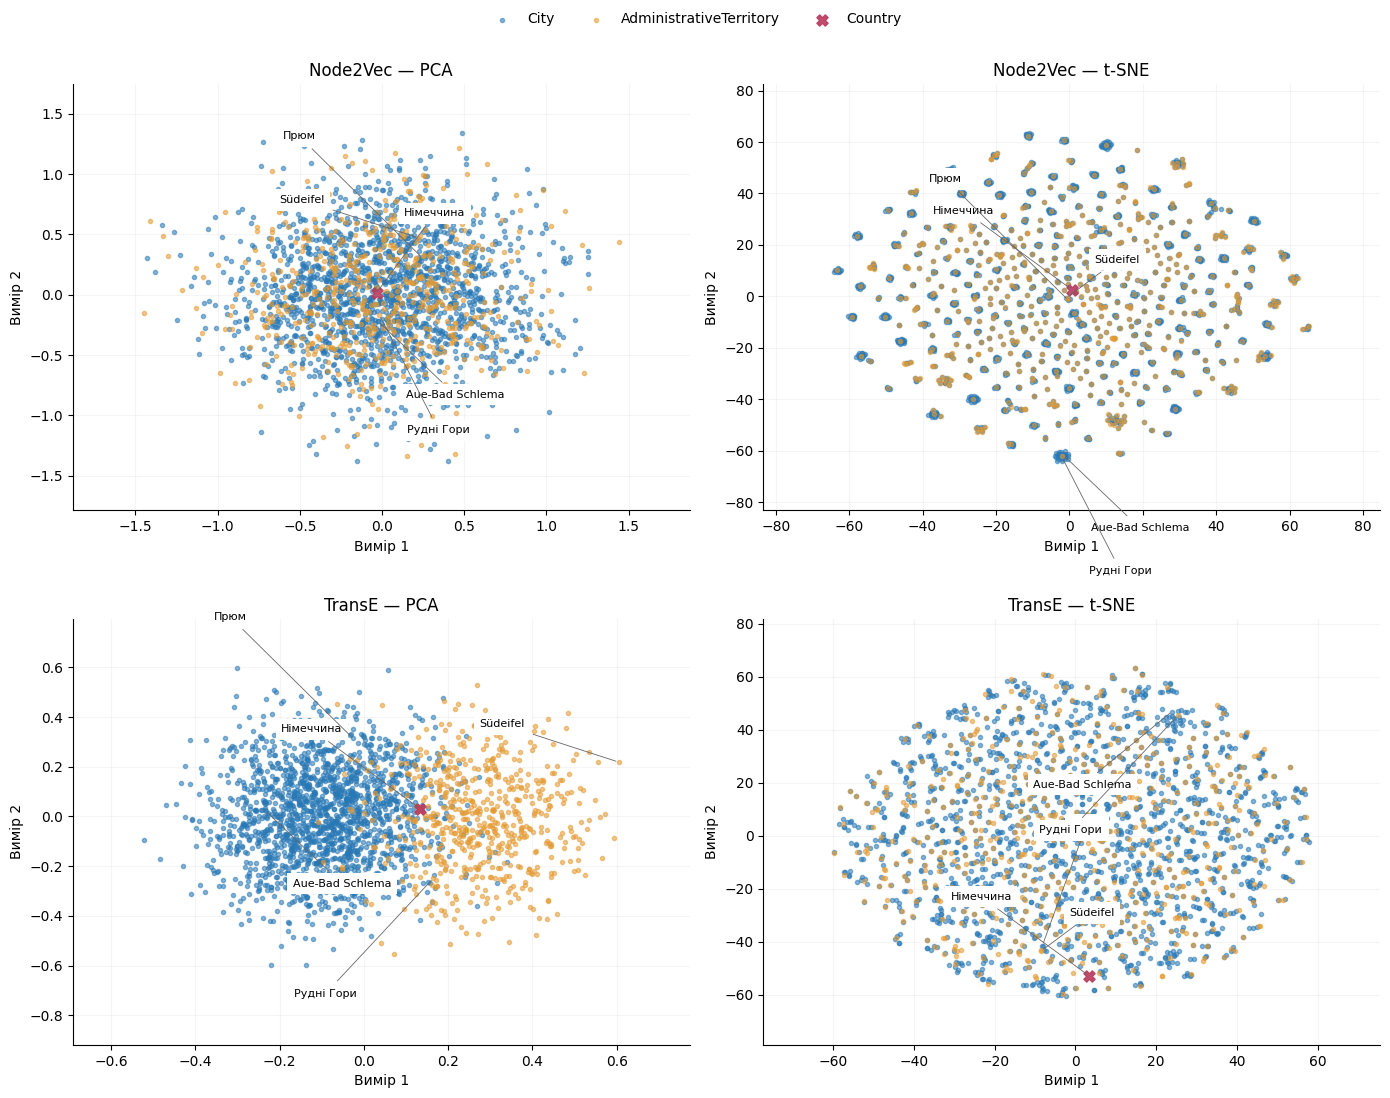

In [13]:
chosen = {"Node2Vec": matrices["U_p1_q1"], "TransE": vectors}
coordinates, projection_metrics = projections(chosen, config)
display(projection_metrics)
figure = plot_projections(coordinates, entities)
plt.show()

**Висновок.** TransE на PCA частково розділяє міста й адміністративні території, Node2Vec на t-SNE утворює локальні групи зі змішаними класами. PCA зберігає лише 7–8% дисперсії, а t-SNE краще передає локальне оточення. Близькість у 2D залежить від проєкції та не гарантує семантичної рівності.

## Завдання 5. Порівняння моделей

In [14]:
def compare_models(
    matrices: dict[str, np.ndarray], entities: pd.DataFrame, graph: nx.Graph
) -> tuple[pd.DataFrame, pd.DataFrame]:
    results = []
    for name, matrix in matrices.items():
        for query in QUERIES:
            neighbors = nearest_neighbors(matrix, entities, graph, query)
            neighbors.insert(0, "model", name)
            results.append(neighbors)
    neighbors = pd.concat(results, ignore_index=True)
    summary = (
        neighbors.groupby(["model", "query", "query_label"], sort=False)
        .agg(
            shared_context_at5=("shared_specific", lambda values: float(values.gt(0).mean())),
            mean_specific_jaccard=("jaccard_specific", "mean"),
        )
        .reset_index()
    )
    return neighbors, summary

In [15]:
neighbors, comparison = compare_models(chosen, entities, graph.to_undirected())
display(neighbors[neighbors["query"].isin((QUERIES[0], QUERIES[2]))])
display(comparison)
print("Спільне оточення рахується без країни; порівнюються сусіди того самого класу.")

,model,query,query_label,neighbor,label,class,cosine,shared_specific,jaccard_specific
0,Node2Vec,Q253696,Прюм,Q553503,Ехтернахербрюк,City,0.8827,1,0.5
1,Node2Vec,Q253696,Прюм,Q543370,Ноєрбург,City,0.8626,1,0.5
2,Node2Vec,Q253696,Прюм,Q544146,Боллендорф,City,0.8434,1,0.5
3,Node2Vec,Q253696,Прюм,Q258974,Бітбург,City,0.8230,1,1.0
4,Node2Vec,Q253696,Прюм,Q570414,Ніденштайн,City,0.6384,0,0.0
10,Node2Vec,Q6339,Рудні Гори,Q9378649,Überlingen VVG,AdministrativeTerritory,0.4958,0,0.0
11,Node2Vec,Q6339,Рудні Гори,Q261407,Баден (земля),AdministrativeTerritory,0.4956,0,0.0
12,Node2Vec,Q6339,Рудні Гори,Q20219,Röbel-Müritz,AdministrativeTerritory,0.4862,0,0.0
13,Node2Vec,Q6339,Рудні Гори,Q453982,Neukloster-Warin,AdministrativeTerritory,0.4852,0,0.0
14,Node2Vec,Q6339,Рудні Гори,Q450095,Artland,AdministrativeTerritory,0.4851,0,0.0


,model,query,query_label,shared_context_at5,mean_specific_jaccard
0,Node2Vec,Q253696,Прюм,0.8,0.50
1,Node2Vec,Q59564401,Aue-Bad Schlema,1.0,1.00
2,Node2Vec,Q6339,Рудні Гори,0.0,0.00
3,Node2Vec,Q15852582,Südeifel,0.2,0.12
4,TransE,Q253696,Прюм,0.4,0.20
5,TransE,Q59564401,Aue-Bad Schlema,0.6,0.60
6,TransE,Q6339,Рудні Гори,0.0,0.00
7,TransE,Q15852582,Südeifel,0.2,0.12


Спільне оточення рахується без країни; порівнюються сусіди того самого класу.


In [16]:
averages = comparison.groupby("model").shared_context_at5.mean()
display(
    Markdown(
        f"**Висновок.** Частка сусідів зі спільним оточенням: Node2Vec — "
        f"{averages['Node2Vec']:.0%}, TransE — {averages['TransE']:.0%}. "
        "Блукання вчать локальний контекст, а TransE — зсув h+r≈t. "
        "Node2Vec підходить для рекомендацій, TransE — для оцінки зв’язків; це описове порівняння на навчальному графі."
    )
)

**Висновок.** Частка сусідів зі спільним оточенням: Node2Vec — 50%, TransE — 30%. Блукання вчать локальний контекст, а TransE — зсув h+r≈t. Node2Vec підходить для рекомендацій, TransE — для оцінки зв’язків; це описове порівняння на навчальному графі.

In [17]:
def write_json(path: Path, value: object) -> None:
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n",
        encoding="utf-8",
        newline="\n",
    )


def export_results(result: dict, output: Path) -> None:
    output.mkdir(parents=True, exist_ok=True)
    entities, triples = result["entities"], result["triples"]
    entities.to_csv(output / "entities.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame(triples, columns=["subject", "predicate", "object"]).to_csv(
        output / "triples.tsv", sep="\t", index=False
    )
    for name, table in result["tables"].items():
        table.to_csv(output / f"{name}.csv", index=False, encoding="utf-8-sig", lineterminator="\n")
    relation_ids = sorted(result["relation_to_id"], key=result["relation_to_id"].get)
    np.savez_compressed(
        output / "embeddings.npz",
        **result["matrices"],
        TransE=result["transe"],
        relations=result["relations"],
        entity_ids=entities.id.to_numpy(dtype=str),
        relation_ids=np.array(relation_ids),
    )
    np.savez_compressed(output / "projections.npz", **result["coordinates"])
    write_json(
        output / "mapping.json",
        {
            "entity_to_id": {node: i for i, node in enumerate(entities.index)},
            "relation_to_id": result["relation_to_id"],
        },
    )
    figure = plot_projections(result["coordinates"], entities)
    figure.savefig(output / "projections.png", dpi=170, bbox_inches="tight")
    plt.close(figure)
    write_json(output / "metrics.json", result["metrics"])

In [18]:
tables = {
    "node2vec_experiments": experiments,
    "sampled_pairs": pairs,
    "translation_examples": examples,
    "translation_summary": translations,
    "projection_metrics": projection_metrics,
    "nearest_neighbors": neighbors,
    "model_comparison": comparison,
    "training_loss": pd.DataFrame({"epoch": range(1, len(losses) + 1), "loss": losses}),
}
metrics = {
    "variant": 12,
    "nodes": len(graph),
    "triples": len(triples),
    "relations": factory.relation_to_id,
    "input_sha256": INPUT_SHA256,
    "config": asdict(config),
    "loss_first": losses[0],
    "loss_last": losses[-1],
}
result = {
    "entities": entities,
    "triples": triples,
    "matrices": matrices,
    "transe": vectors,
    "relations": relations,
    "relation_to_id": factory.relation_to_id,
    "coordinates": coordinates,
    "tables": tables,
    "metrics": metrics,
}
export_results(result, OUT)
assert all(
    np.isfinite(matrix).all() and matrix.shape == (len(entities), config.dimensions)
    for matrix in [*matrices.values(), vectors]
)
assert np.array_equal(matrices["D_p1_q1"], matrices["D_p0.5_q2"])
assert np.array_equal(matrices["D_p1_q1"], matrices["D_p2_q0.5"])
print("Результати збережено в outputs/.")

Результати збережено в outputs/.
